# Bayesian Factorization of the Lung Cancer Data: Gibbs and CAVI

This notebook adapts `Lung_cancer_GS.ipynb` and `Lung_cancer_VI.ipynb` to the repository's JAX `bfm` interface for analyzing `lung.npy`. The model is $x_i=B\eta_i+\epsilon_i$, with an $L_{1/2}$ increasing-shrinkage prior on the loadings and truncation level $K=50$.

The analysis covers fitting and diagnostics for both methods, factor selection using 95% marginal intervals, Rotation-Sign-Permutation (RSP) alignment (varimax + sign/permutation), loading-column norms, and scatter plots of the first two factor scores for four sample groups. Factor selection is performed in the original prior coordinates; RSP is used only to obtain a consistent orientation for visualization.

In [1]:
import os

MODE = "cpu"
if MODE not in {"cpu", "gpu"}:
    raise ValueError('MODE must be "cpu" or "gpu".')
os.environ["JAX_PLATFORMS"] = "cpu" if MODE == "cpu" else "cuda,cpu"

import jax

backend = jax.default_backend()
if backend != MODE:
    raise RuntimeError("Device mode has changed: restart the kernel and run all cells.")
print("Backend:", backend)
print("Devices:", jax.devices())

Backend: cpu
Devices: [CpuDevice(id=0)]


## 1. Data and Shared Settings

The data comprise 56 samples and 5,000 genes. The samples are ordered as Carcinoid (20), Colon (13), Normal (17), and Small cell (6). Both methods center the data in float64 before converting them to float32 for fitting, and use the same prior hyperparameters as in the paper.

In [2]:
import sys
import time
from pathlib import Path

%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np

root = next(
    (d for d in (Path.cwd(), *Path.cwd().parents) if (d / "bfm").is_dir()),
    None,
)
if root is None:
    raise FileNotFoundError("Could not locate the repository root containing bfm/.")
if str(root) not in sys.path:
    sys.path.insert(0, str(root))

from bfm import CaviBFM, GibbsBFM

K = 50
LEVEL = 0.95
SEED = 2026
X = np.load(root / "lung" / "lung.npy", allow_pickle=False)
if X.shape != (56, 5000):
    raise ValueError(f"Expected X.shape == (56, 5000), got {X.shape}.")
if not np.isfinite(X).all():
    raise ValueError("X contains NaN or infinity.")

GROUPS = (
    ("Carcinoid", 0, 20, "orange", "s"),
    ("Colon", 20, 33, "blue", "o"),
    ("Normal", 33, 50, "green", "^"),
    ("Small cell", 50, 56, "black", "*"),
)
plt.rcParams.update({
    "figure.dpi": 110,
    "savefig.dpi": 140,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "font.size": 10,
})
np.set_printoptions(precision=4, suppress=True, linewidth=150)

print(f"Repository: {root}")
print(f"X: {X.shape}, dtype={X.dtype}, range=({X.min():.4f}, {X.max():.4f})")
print(f"K={K}, credible level={LEVEL}, seed={SEED}")

Repository: C:\Users\kexio\Desktop\GitHub\LH_BFM
X: (56, 5000), dtype=float64, range=(-6.6776, 7.1188)
K=50, credible level=0.95, seed=2026


## 2. CAVI Fitting and ELBO Diagnostics

CAVI updates the factor scores, loadings, shrinkage moments, and noise variances in sequence, evaluating the closed-form ELBO from Appendix B2 after each complete sweep. Here, `tol=0.1` with a maximum of 1,000 sweeps.

In [3]:
t0 = time.perf_counter()
vi = CaviBFM(
    K = K,
    a= 10.0,
    c1= 2.0,
    c2= 1.0,
    a_sigma = 1.0,
    b_sigma = 1.0,
    center = False,
    max_iter = 1000,
    tol = 1e-1,
    drop_budget = 0.5,
    verbose=False,
).fit(X)
vi_wall = time.perf_counter() - t0

assert vi.mu_.shape == (X.shape[1], K)
assert vi.W_.shape == (X.shape[0], K)
assert vi.V_.shape == (X.shape[1], K, K)
assert np.isfinite(vi.elbo_).all()
print(
    f"CAVI: converged={vi.converged_} ({vi.stop_reason_}), "
    f"sweeps={vi.n_iter_}, final ELBO={vi.elbo_[-1]:.4f}"
)
print(
    f"CAVI timing: compile={vi.compile_sec_:.2f}s, "
    f"loop={vi.runtime_sec_:.2f}s, wall={vi_wall:.2f}s"
)

CAVI: converged=True (tol), sweeps=962, final ELBO=-483058.7353
CAVI timing: compile=0.42s, loop=176.44s, wall=179.67s


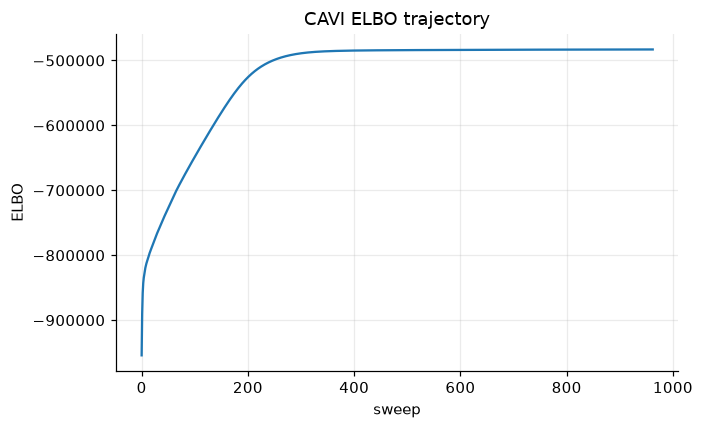

In [4]:
fig, ax = plt.subplots(figsize=(6.5, 4.0))
vi.plot_elbo(ax=ax, show=False, title="CAVI ELBO trajectory")
plt.show()

## 3. Gibbs Posterior Sampling and ESS

The Gibbs sampler runs 20,000 sweeps, discards the first 10,000 as burn-in, and retains every 10th draw thereafter, yielding 1,000 posterior draws. ESS is computed from the raw, unaligned draws. To bound ArviZ's temporary memory usage, the loading and noise-variance diagnostics use a deterministic subset containing every 25th gene; factor selection still uses all 5,000 genes.

In [5]:
t0 = time.perf_counter()
gs = GibbsBFM(
    K = K,
    a = 10.0,
    c1 = 2.0,
    c2 = 1.0,
    a_sigma = 1.0,
    b_sigma = 1.0,
    center = False,
    n_iter = 20000,
    burn_in = 10000,
    thin = 10,
    seed = SEED,
    graph = False,
    verbose = True,
).fit(X)
gs_wall = time.perf_counter() - t0

S = gs.B_samples_.shape[0]
assert S == 1000
assert gs.B_samples_.shape == (S, X.shape[1], K)
assert gs.sigma2_samples_.shape == (S, X.shape[1])
assert np.isfinite(gs.B_samples_).all()
assert np.isfinite(gs.sigma2_samples_).all()
print(
    f"Gibbs: kept={S}, gamma={gs.gamma_mode_}, "
    f"chi2_normals={gs.chi2_normals_}"
)
print(f"Gibbs timing: loop={gs.runtime_sec_:.2f}s, wall={gs_wall:.2f}s")

GS_LH: sweep 2104/20000


GS_LH: sweep 4208/20000


GS_LH: sweep 6312/20000


GS_LH: sweep 8416/20000


GS_LH: sweep 12630/20000


GS_LH: sweep 15260/20000


GS_LH: sweep 17890/20000


GS_LH: sweep 20000/20000


Gibbs: kept=1000, gamma=exact, chi2_normals=0
Gibbs timing: loop=1754.17s, wall=1764.00s


In [6]:
from bfm._gs import ess_summary as gibbs_ess_summary

ESS_STRIDE = 25
ess_gs = gibbs_ess_summary(
    gs.B_samples_[:, ::ESS_STRIDE, :],
    gs.sigma2_samples_[:, ::ESS_STRIDE],
    method="bulk",
)
print(f"Bulk ESS summary (every {ESS_STRIDE}th gene; 200 genes total):")
for name, stats in ess_gs.items():
    print(
        f"  {name}: min={stats['min']:.1f}, median={stats['median']:.1f}, "
        f"mean={stats['mean']:.1f}, max={stats['max']:.1f}"
    )
print("Constant or nearly constant columns can have misleading ESS and need separate inspection.")

Bulk ESS summary (every 25th gene; 200 genes total):
  B: min=10.7, median=950.8, mean=918.9, max=1291.9
  sigma2: min=567.1, median=932.8, mean=929.8, max=1206.3
Constant or nearly constant columns can have misleading ESS and need separate inspection.


## 4. Marginal Factor Selection in the Original Coordinates

A loading entry is active if its 95% marginal interval excludes zero. For each column, we report the proportion of active entries across all 5,000 genes; columns with at least one active entry are counted as factors. Gibbs uses the same shortest-HPD-window rule as `BaseBFM.active_entries()`, but processes genes in blocks to avoid converting and sorting all draws in float64 at once. CAVI uses Gaussian marginal intervals directly.

In [7]:
def gibbs_active_entries_hpd(draws, level=0.95, chunk_genes=250):
    draws = np.asarray(draws)
    S, p, K_ = draws.shape
    if S < 2:
        raise ValueError("At least two draws are required.")
    m = int(np.ceil(level * S))
    active = np.empty((p, K_), dtype=bool)
    for start in range(0, p, chunk_genes):
        stop = min(start + chunk_genes, p)
        sorted_draws = np.sort(
            np.asarray(draws[:, start:stop, :], dtype=np.float64), axis=0
        )
        if m >= S:
            lo, hi = sorted_draws[0], sorted_draws[-1]
        else:
            widths = sorted_draws[m - 1:] - sorted_draws[:S - m + 1]
            idx = np.argmin(widths, axis=0)
            lo = np.take_along_axis(sorted_draws, idx[None], axis=0)[0]
            hi = np.take_along_axis(sorted_draws, (idx + m - 1)[None], axis=0)[0]
        active[start:stop] = (lo > 0) | (hi < 0)
    return active


gs_active = gibbs_active_entries_hpd(gs.B_samples_, level=LEVEL)
vi_active = vi.active_entries(level=LEVEL, use_aligned=False)
gs_activity = gs_active.mean(axis=0, dtype=np.float64)
vi_activity = vi_active.mean(axis=0, dtype=np.float64)
r_gs = int(gs_active.any(axis=0).sum())
r_vi = int(vi_active.any(axis=0).sum())

print(f"Gibbs active factors (95% marginal HPD): {r_gs}")
print(gs_activity)
print(f"CAVI active factors (95% Gaussian marginal CI): {r_vi}")
print(vi_activity)

Gibbs active factors (95% marginal HPD): 21
[0.148  0.2508 0.1602 0.1606 0.2124 0.0964 0.1264 0.1222 0.0556 0.021  0.0588 0.0326 0.059  0.0266 0.0136 0.0264 0.07   0.0154 0.0114 0.024  0.0134
 0.     0.     0.     0.     0.     0.     0.     0.     0.     0.     0.     0.     0.     0.     0.     0.     0.     0.     0.     0.     0.
 0.     0.     0.     0.     0.     0.     0.     0.    ]
CAVI active factors (95% Gaussian marginal CI): 33
[0.6636 0.5928 0.4062 0.3654 0.4246 0.397  0.3298 0.1242 0.24   0.1312 0.235  0.1442 0.2206 0.2032 0.1588 0.1502 0.2314 0.1096 0.0972 0.1178 0.1304
 0.0932 0.1068 0.1378 0.1532 0.0946 0.1048 0.0762 0.104  0.09   0.074  0.0484 0.0682 0.     0.     0.     0.     0.     0.     0.     0.     0.
 0.     0.     0.     0.     0.     0.     0.     0.    ]


## 5. RSP Alignment and Factor Scores

Varimax + sign/permutation post-processing is applied separately to the two fits. With `K=50`, the default assignment backend automatically uses the Optax Hungarian solver. For Gibbs, `B_hat_` is updated to the mean of the aligned draws; for CAVI, the original variational parameters remain unchanged, and aligned representations are exposed through attributes such as `mu_aligned_` and `eta_aligned_`.

In [8]:
t0 = time.perf_counter()
gs.align_factors(assignment_backend="auto", verbose=False)
gs_rsp_wall = time.perf_counter() - t0

t0 = time.perf_counter()
vi.align_factors(assignment_backend="auto", verbose=False)
vi_rsp_wall = time.perf_counter() - t0

alignment_summary = {}
for name, model in (("Gibbs", gs), ("CAVI", vi)):
    result = model.rsp_result_
    status = int(result.status_code)
    if status == 4:
        raise FloatingPointError(f"{name} RSP returned non-finite outputs.")
    alignment_summary[name] = {
        "status": status,
        "n_iter": int(result.n_iter),
        "loss_final": float(result.loss_final),
    }
    print(
        f"{name} RSP: status={status}, iterations={int(result.n_iter)}, "
        f"final loss={float(result.loss_final):.6g}"
    )
print(f"RSP wall time: Gibbs={gs_rsp_wall:.2f}s, CAVI={vi_rsp_wall:.2f}s")
assert gs.B_aligned_.shape == gs.B_samples_.shape
assert vi.mu_aligned_.shape == vi.mu_.shape
assert np.isfinite(gs.B_aligned_).all()
assert np.isfinite(vi.mu_aligned_).all()

Gibbs RSP: status=1, iterations=2, final loss=535312
CAVI RSP: status=1, iterations=2, final loss=0
RSP wall time: Gibbs=172.70s, CAVI=4.66s


In [9]:
scores = gs.sample_factors(
    X,
    return_eta=True,
    return_eta_aligned=True,
    seed=SEED,
    batch_size=32,
)
eta_raw = scores["eta_sample"]
eta_aligned = scores["eta_sample_aligned"]
eta_gs_mean = eta_aligned.mean(axis=0, dtype=np.float64)
eta_vi_mean = np.asarray(vi.eta_aligned_, dtype=np.float64)

assert eta_raw.shape == eta_aligned.shape == (S, K, X.shape[0])
assert eta_gs_mean.shape == eta_vi_mean.shape == (K, X.shape[0])
assert np.isfinite(eta_raw).all() and np.isfinite(eta_aligned).all()

draw_index = 0
np.testing.assert_allclose(
    gs.B_aligned_[draw_index] @ eta_aligned[draw_index],
    gs.B_samples_[draw_index] @ eta_raw[draw_index],
    rtol=2e-4,
    atol=2e-4,
)
np.testing.assert_allclose(
    vi.mu_aligned_ @ vi.eta_aligned_,
    vi.mu_ @ vi.W_.T,
    rtol=2e-4,
    atol=2e-4,
)
print("RSP reconstruction checks passed for Gibbs and CAVI.")
print("Gibbs aligned scores:", eta_aligned.shape, "(S, K, n)")

RSP reconstruction checks passed for Gibbs and CAVI.
Gibbs aligned scores: (1000, 50, 56) (S, K, n)


## 6. Loading-Column Norms and Sample Factor-Score Plots

Loading norms are computed from the RSP-aligned point estimates. For Gibbs, factor scores are sampled conditionally for each retained draw and then averaged in the aligned coordinates; CAVI uses the aligned variational mean scores.

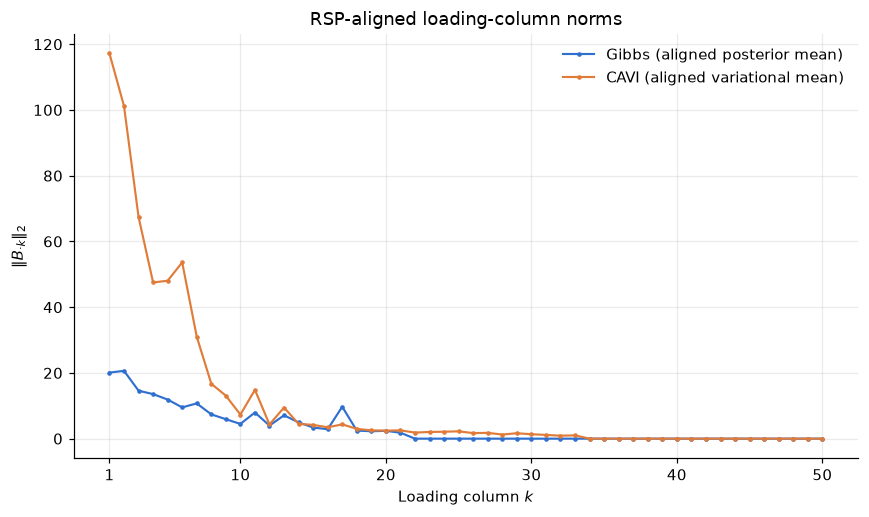

In [10]:
column_index = np.arange(1, K + 1)
norm_gs = np.linalg.norm(np.asarray(gs.B_hat_, dtype=np.float64), axis=0)
norm_vi = np.linalg.norm(np.asarray(vi.mu_aligned_, dtype=np.float64), axis=0)

fig, ax = plt.subplots(figsize=(8, 4.8))
for norms, label, color in (
    (norm_gs, "Gibbs (aligned posterior mean)", "#2f6fd0"),
    (norm_vi, "CAVI (aligned variational mean)", "#e07b39"),
):
    ax.plot(column_index, norms, color=color, lw = 1.4, marker=".", ms = 4, label=label)
ax.set_title("RSP-aligned loading-column norms")
ax.set_xlabel("Loading column $k$")
ax.set_ylabel(r"$\|B_{\cdot k}\|_2$")
ax.set_xticks([1, 10, 20, 30, 40, 50])
ax.legend(frameon=False)
fig.tight_layout()
plt.show()

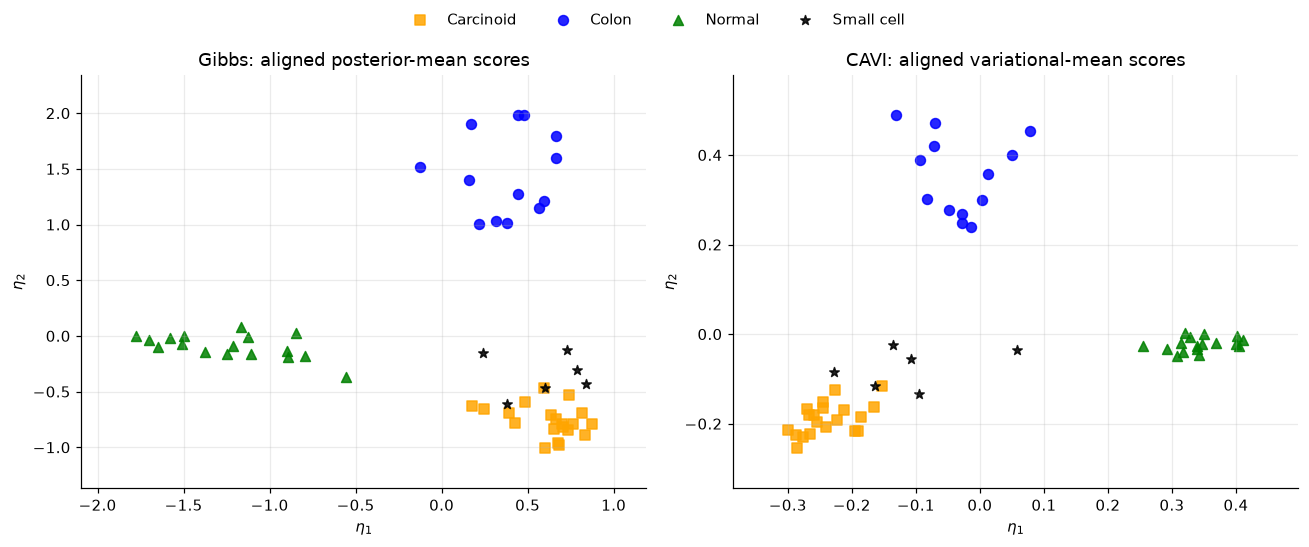

In [11]:
def plot_factor_scores(ax, eta, title):
    for label, start, stop, color, marker in GROUPS:
        ax.scatter(
            eta[0, start:stop],
            eta[1, start:stop],
            c=color,
            marker=marker,
            s = 42,
            alpha=0.85,
            label=label,
        )
    ax.set_title(title)
    ax.set_xlabel(r"$\eta_1$")
    ax.set_ylabel(r"$\eta_2$")
    ax.margins(x=0.12, y=0.12)


fig, axes = plt.subplots(1, 2, figsize=(12, 5.0))
plot_factor_scores(axes[0], eta_gs_mean, "Gibbs: aligned posterior-mean scores")
plot_factor_scores(axes[1], eta_vi_mean, "CAVI: aligned variational-mean scores")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=4, frameon=False)
fig.tight_layout(rect=(0, 0, 1, 0.94))
plt.show()

## 7. Run Summary

The following summary is generated from the actual run. Factor counts in the original coordinates reflect the marginal-interval rule under the increasing-shrinkage prior; RSP status describes only the post-processing and does not alter the fitted results in those coordinates.

In [12]:
print("Lung cancer analysis summary")
print("=" * 32)
print(
    f"Gibbs: {S} kept draws, active factors={r_gs}, "
    f"fit wall={gs_wall:.1f}s, RSP status={alignment_summary['Gibbs']['status']}"
)
print(
    f"CAVI: {vi.n_iter_} sweeps, converged={vi.converged_}, "
    f"active factors={r_vi}, fit wall={vi_wall:.1f}s, "
    f"RSP status={alignment_summary['CAVI']['status']}"
)
print(
    f"Bulk ESS median (200-gene subset): "
    f"B={ess_gs['B']['median']:.1f}, sigma2={ess_gs['sigma2']['median']:.1f}"
)
print("All requested fits, figures, and numerical checks completed.")

Lung cancer analysis summary
Gibbs: 1000 kept draws, active factors=21, fit wall=1764.0s, RSP status=1
CAVI: 962 sweeps, converged=True, active factors=33, fit wall=179.7s, RSP status=1
Bulk ESS median (200-gene subset): B=950.8, sigma2=932.8
All requested fits, figures, and numerical checks completed.
